In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor, ExtraTreesRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Shape: (10000, 6)
Missing values:
 Extracurricular Activities          1572
Sample Question Papers Practiced    2856
dtype: int64
Duplicates: 132
count    10000.000000
mean        55.224800
std         19.212558
min         10.000000
25%         40.000000
50%         55.000000
75%         71.000000
max        100.000000
Name: Performance Index, dtype: float64


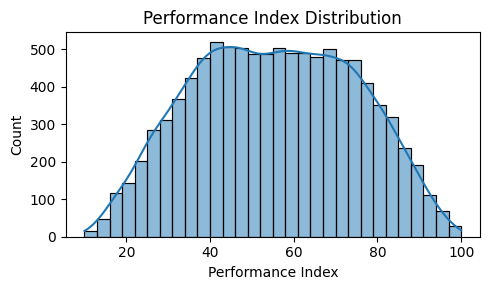

In [2]:
# 1. Data Understanding & EDA
df = pd.read_csv("Student_Performance.csv")
print("Shape:", df.shape)
print("Missing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("Duplicates:", df.duplicated().sum())
print(df["Performance Index"].describe())

plt.figure(figsize=(5, 3))
sns.histplot(df["Performance Index"].dropna(), bins=30, kde=True)
plt.title("Performance Index Distribution")
plt.tight_layout()
plt.show()

In [3]:
# 2. Data Cleaning & Feature Engineering
df = df.drop_duplicates().dropna(subset=["Performance Index"]).copy()
df["study_x_prev"] = df["Hours Studied"] * df["Previous Scores"] / 100.0

X = df.drop(columns=["Performance Index"])
y = df["Performance Index"]

In [4]:
# 3. Train/Test Split & Preprocessing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
])

In [5]:
# 4. Models Comparison
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(max_iter=2000),
    "ElasticNet": ElasticNet(max_iter=2000),
    "KNN Regressor": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "SVR": SVR(),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "AdaBoost": AdaBoostRegressor(random_state=42),
    "Extra Trees": ExtraTreesRegressor(n_estimators=100, random_state=42)
}

results = []
for name, reg in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", reg)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    results.append({
        "Model": name,
        "MAE": round(mean_absolute_error(y_test, y_pred), 2),
        "MSE": round(mse, 2),
        "RMSE": round(np.sqrt(mse), 2),
        "R2": round(r2_score(y_test, y_pred), 4)
    })

comp_df = pd.DataFrame(results).sort_values(by="R2", ascending=False)
display(comp_df)

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,1.65,4.31,2.08,0.9886
1,Ridge,1.65,4.31,2.08,0.9886
8,Gradient Boosting,1.76,4.83,2.20,0.9872
6,Random Forest,1.93,5.85,2.42,0.9845
7,SVR,1.90,6.00,2.45,0.9841
10,Extra Trees,2.14,7.17,2.68,0.9811
9,AdaBoost,2.21,7.74,2.78,0.9795
4,KNN Regressor,2.43,9.05,3.01,0.9761
2,Lasso,2.42,9.45,3.07,0.9750
5,Decision Tree,2.44,9.53,3.09,0.9748


In [6]:
# 5. GridSearchCV on Best Model
best_name = comp_df.iloc[0]["Model"]
best_r2_before = comp_df.iloc[0]["R2"]
param_grids = {
    "Random Forest": {"model__n_estimators": [100, 150], "model__max_depth": [None, 12]},
    "Extra Trees": {"model__n_estimators": [100, 150], "model__max_depth": [None, 12]},
    "Gradient Boosting": {"model__n_estimators": [100, 150], "model__learning_rate": [0.05, 0.1]},
    "Decision Tree": {"model__max_depth": [None, 8, 12]},
    "KNN Regressor": {"model__n_neighbors": [3, 5, 7]},
    "Ridge": {"model__alpha": [0.1, 1.0, 10.0]},
    "Lasso": {"model__alpha": [0.1, 1.0, 10.0]},
    "ElasticNet": {"model__alpha": [0.1, 1.0]},
    "SVR": {"model__C": [1.0, 10.0]},
    "AdaBoost": {"model__n_estimators": [50, 100]}
}

grid = GridSearchCV(
    Pipeline([("prep", preprocessor), ("model", models[best_name])]),
    param_grid=param_grids.get(best_name, {}),
    cv=5, scoring="r2", n_jobs=-1
)
grid.fit(X_train, y_train)
print("Best Model:", best_name)
print("best_params_:", grid.best_params_)
print("best_score_:", round(grid.best_score_, 4))

Best Model: Linear Regression
best_params_: {}
best_score_: 0.9882


R2 Before Tuning: 0.9886 | After Tuning: 0.9886


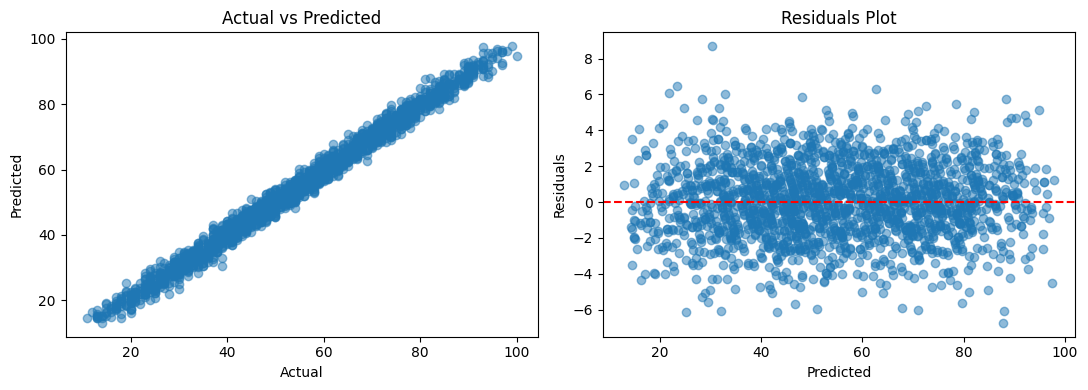

In [7]:
# 6. Final Evaluation & Plots
best_model = grid.best_estimator_
y_pred_best = best_model.predict(X_test)
print(f"R2 Before Tuning: {best_r2_before:.4f} | After Tuning: {r2_score(y_test, y_pred_best):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, y_pred_best, alpha=0.5)
axes[0].set_title("Actual vs Predicted")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted")

axes[1].scatter(y_pred_best, y_test - y_pred_best, alpha=0.5)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_title("Residuals Plot")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Residuals")
plt.tight_layout()
plt.show()